# 01 - Data collection and exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = '../data/raw/spotify_songs.csv'
pd.set_option('display.float_format', '{:.2f}'.format)

## 1. Thu thập dữ liệu

### Chủ đề & Bối cảnh thực tế 
- Chủ đề: Metadata âm nhạc số và các đặc trưng âm thanh định lượng của 32.833 bản ghi bài hát trên nền tảng Spotify, với 23 cột được chia thành 4 nhóm chính theo bảng mô tả của TidyTuesday:
  1. **Định danh bài hát & album (6 cột):** `track_id`, `track_name`, `track_artist`, `track_album_id`, `track_album_name`, `track_album_release_date`.
  2. **Phân loại theo playlist (4 cột):** `playlist_name`, `playlist_id`, `playlist_genre` (6 thể loại chính), `playlist_subgenre` (24 tiểu thể loại).
  3. **Chỉ số mức độ phổ biến (1 cột):** `track_popularity` (thang điểm 0–100 phản ánh độ thịnh hành của bài hát).
  4. **Đặc trưng âm thanh trích xuất từ Spotify API (12 cột):** `danceability`, `energy`, `key`, `loudness`, `mode`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, và `duration_ms`.
- Bối cảnh thực tế: Các nền tảng phát nhạc trực tuyến hiện đại như Spotify ứng dụng lĩnh vực Truy xuất Thông tin Âm nhạc (MIR) để lượng hóa cảm nhận âm nhạc trừu tượng thành các thông số kỹ thuật có cấu trúc. Bộ dữ liệu này phản ánh cách nền tảng dùng đặc trưng tín hiệu âm thanh kết hợp hành vi tuyển chọn playlist để vận hành hệ thống gợi ý và phân tích thị hiếu người nghe theo từng dòng nhạc.

### Nguồn dữ liệu
- **Bản gốc (TidyTuesday):** Dữ liệu từ **Spotify AB**, do **Kaylin Pavlik** thu thập và cộng đồng **R4DS** công bố ngày **21/01/2020** tại [https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-01-21](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-01-21).
- **Bản tải về (Kaggle):** Được **Joakim Arvidsson** (`joebeachcapital`) đăng tải lại năm **2023** tại [https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs](https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs).

### Giấy phép sử dụng
- **Kho lưu trữ gốc (TidyTuesday):** Phát hành theo giấy phép **CC0-1.0** (Public Domain), cho phép tự do sao chép, chỉnh sửa và khai thác cho cả mục đích học thuật lẫn thương mại.
- **Bản phân phối (Kaggle):** Áp dụng **Open Database License (ODbL v1.0)**, yêu cầu ghi nhận nguồn đóng góp (R4DS, Kaylin Pavlik, Joakim Arvidsson) và duy trì tính mở nếu tái phân phối cơ sở dữ liệu phái sinh.
- **Ràng buộc bản quyền (Spotify Web API):** Dữ liệu gốc chịu sự điều chỉnh của **Spotify Developer Terms of Service**.

### Phương pháp thu thập & Thiên lệch dữ liệu
- **Cơ chế thu thập:** Truy xuất tự động qua **Spotify Web API** bằng gói thư viện `spotifyr` (R) từ các playlist công khai; tiêu chí chọn playlist được tác giả trình bày chi tiết trong bài blog đính kèm tại README gốc.
-  Lấy mẫu ~5.000 bản ghi cho mỗi thể loại trong **6 thể loại chính** (*EDM, Latin, Pop, R&B, Rap, Rock* — chia thành 24 tiểu thể loại), tổng cộng **32.833 dòng** nhưng chỉ **28.356 bài hát** khác nhau. Ngày phát hành trải dài từ **1957 đến 01/2020**, nhưng cấu trúc playlist và chỉ số `track_popularity` là ảnh chụp tĩnh tại **tháng 01/2020**.
- **Hạn chế & Biases:**
  - **Nhiễu nhãn thể loại (*Label Noise*):** Nhãn `playlist_genre` được kế thừa từ playlist chứa bài hát thay vì thể loại gốc của nghệ sĩ.
  - **Trùng lặp bản ghi (*Multi-playlist Duplication*):** Các bài hát phổ biến xuất hiện ở nhiều playlist gây trùng lặp `track_id` (4.477 dòng lặp lại `track_id`).
  - **Thiên lệch chọn mẫu & văn hóa (*Sampling Bias*):** Tập trung vào 6 dòng nhạc thương mại phổ biến trên Spotify khiến dữ liệu chủ yếu là nhạc Âu - Mỹ (US-UK) và loại trừ hoàn toàn các dòng nhạc ngoài danh mục và tiếng nước ngoài. (*Jazz, Classical, Folk...*).
  - **Thiên lệch thời gian (*Recency Bias*):** Điểm `track_popularity` (0–100) ưu tiên lượt phát gần thời điểm thu thập (01/2020), có thể làm giảm đáng kể điểm số của các bản thu thập niên 1950–1990 (sẽ kiểm tra ở phần khám phá)
  - **Khuyết dữ liệu & Sai lệch định dạng:** Tồn tại 5 bản ghi khuyết (`NA`) ở thông tin định danh và sự không đồng nhất định dạng thời gian ở `track_album_release_date` (`YYYY`, `YYYY-MM-DD` và `YYYY-MM`).
### Lý do chọn bộ dữ liệu
- **Cân bằng giữa quy mô và chiều sâu đặc trưng:** Với 32.833 quan sát cùng 23 thuộc tính kết hợp cả biến phân loại phân cấp (`playlist_genre`, `playlist_subgenre`), biến thời gian, biến mục tiêu (`track_popularity`) và 12 đặc trưng âm thanh liên tục, bộ dữ liệu đủ lớn và đa dạng để thực hiện trọn vẹn quy trình từ EDA, kiểm định thống kê đến xây dựng mô hình học máy.
- **Tính diễn giải trực quan:** Các đặc trưng như độ sôi động (`energy`), độ tích cực cảm xúc (`valence`), nhịp độ (`tempo`) hay độ ồn (`loudness`) dễ liên hệ thực tế, giúp nhóm diễn giải rõ ràng các phát hiện phân tích.
- **Cơ hội rèn luyện tiền xử lý thực tế:** Bộ dữ liệu chứa các vấn đề thực tế như trùng lặp `track_id` do giao thoa playlist, định dạng ngày phát hành không đồng nhất và phân phối lệch mạnh ở các biến như `instrumentalness`, `speechiness` — phù hợp để thể hiện kỹ thuật làm sạch và biến đổi dữ liệu.

In [2]:
df = pd.read_csv(DATA)
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.63,1,0.06,0.10,0.00,0.07,0.52,122.04,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.97,1,0.04,0.07,0.00,0.36,0.69,99.97,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.43,0,0.07,0.08,0.00,0.11,0.61,124.01,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.78,1,0.10,0.03,0.00,0.20,0.28,121.96,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.67,1,0.04,0.08,0.00,0.08,0.72,123.98,189052


# 2. Khám phá dữ liệu

## 2.1 Overview

In [3]:
df.shape

(32833, 23)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [5]:
df.isna().all(axis=1).sum()

np.int64(0)

### Ý nghĩa từng cột và kiểu dữ liệu mong muốn
| STT | Tên cột | Ý nghĩa | Kiểu dữ liệu mong muốn |
| :--- | :--- | :--- | :--- |
| 0 | `track_id` | ID định danh bài hát. | `str` |
| 1 | `track_name` | Tên bài hát. | `str` |
| 2 | `track_artist` | Tên nghệ sĩ. | `str` |
| 3 | `track_popularity` | Mức độ phổ biến (0–100) do Spotify tính từ lượt phát và nghiêng về lượt nghe gần đây (tại thời điểm 01/2020). | `int64` |
| 4 | `track_album_id` | ID định danh của album. | `str` |
| 5 | `track_album_name` | Tên của album. | `str` |
| 6 | `track_album_release_date` | Ngày phát hành của album. | `datetime64` |
| 7 | `playlist_name` | Tên của danh sách phát (playlist). | `str` |
| 8 | `playlist_id` | ID định danh của danh sách phát. | `str` |
| 9 | `playlist_genre` | Thể loại chính của danh sách phát (6 nhóm). | `category` |
| 10 | `playlist_subgenre` | Tiểu thể loại của danh sách phát (24 nhóm). | `category` |
| 11 | `danceability` | Mức độ phù hợp để nhảy (0 -> 1); chỉ dùng so sánh tương đối, không có ngưỡng cứng. | `float64` |
| 12 | `energy` | Cường độ và sự sôi động cảm nhận được (0 -> 1); chỉ dùng so sánh tương đối, không có ngưỡng cứng. | `float64` |
| 13 | `key` | Cao độ (tông nhạc) ước tính (0–11; bằng -1 nếu không phát hiện được tông). | `category` |
| 14 | `loudness` | Âm lượng trung bình toàn bài tính bằng decibel (dB), thường nằm trong khoảng [-60, 0] dB. | `float64` |
| 15 | `mode` | Điệu thức của bài hát: Trưởng (Major) = 1, Thứ (Minor) = 0. | `category` |
| 16 | `speechiness` | Mức độ xuất hiện lời nói (0 -> 1). Ngưỡng Spotify: `< 0.33` nhạc, `0.33–0.66` nhạc lẫn lời nói (rap), `> 0.66` gần như toàn lời nói. | `float64` |
| 17 | `acousticness` | Độ tin cậy (0.0 -> 1.0) cho biết bài hát có phải nhạc acoustic hay không (không phải lượng nhạc cụ acoustic). | `float64` |
| 18 | `instrumentalness` | Độ tin cậy (0.0 -> 1.0) dự đoán bài hát là nhạc không lời; `> 0.5` được xem là nhạc không lời (tiếng ngân nga "ooh/aah" tính là nhạc cụ, rap/lời nói tính là có giọng hát). | `float64` |
| 19 | `liveness` | Độ tin cậy (0.0 -> 1.0) phát hiện khán giả trong bản thu; `> 0.8` cho thấy khả năng rất cao là bản thu trực tiếp (live). | `float64` |
| 20 | `valence` | Sắc thái tích cực về mặt cảm xúc (0 -> 1: cao là vui/tươi sáng, thấp là buồn/u uất); chỉ dùng so sánh tương đối. | `float64` |
| 21 | `tempo` | Nhịp độ ước tính tính bằng số phách/phút (BPM); chỉ dùng so sánh tương đối. | `float64` |
| 22 | `duration_ms` | Thời lượng của bài hát tính bằng mili-giây (ms). | `int64` |

### Kiểm tra định dạng dữ liệu các cột ta sẽ đổi kiểu

In [6]:
df['track_album_release_date'].str.len().value_counts()

track_album_release_date
10    30947
4      1855
7        31
Name: count, dtype: int64

In [7]:
sorted(df['key'].unique().tolist())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

In [8]:
sorted(df['mode'].unique().tolist())

[0, 1]

### Kiểm tra trùng lặp + tìm khóa chính

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.duplicated(subset=['track_id']).sum()

np.int64(4477)

In [11]:
df.duplicated(subset=['track_id', 'playlist_id']).sum()

np.int64(582)

In [12]:
dups = df[df.duplicated(subset=['track_id', 'playlist_id'], keep=False)].sort_values(['track_id', 'playlist_id'])

diff_cols = [col for col in df.columns if dups.groupby(['track_id', 'playlist_id'])[col].nunique().max() > 1]
print("Các cột gây khác biệt:", diff_cols)

dups[['track_id', 'playlist_id'] + diff_cols].head(10)

Các cột gây khác biệt: ['playlist_genre', 'playlist_subgenre']


,track_id,playlist_id,playlist_genre,playlist_subgenre
12979,01R0Xdwje645C6xFCnMRvm,3Ho3iO0iJykgEQNbjB2sic,rock,classic rock
15244,01R0Xdwje645C6xFCnMRvm,3Ho3iO0iJykgEQNbjB2sic,rock,hard rock
27979,037yW9RzsLze4OmBYmcH4G,6KnQDwp0syvhfHOR4lWP7x,edm,electro house
31042,037yW9RzsLze4OmBYmcH4G,6KnQDwp0syvhfHOR4lWP7x,edm,progressive electro house
27251,04wllvXvWOkZS5NugzeS8O,25ButZrVb1Zj1MJioMs09D,edm,electro house
29979,04wllvXvWOkZS5NugzeS8O,25ButZrVb1Zj1MJioMs09D,edm,pop edm
28033,06qKEP3ITnVPmH2ZW1zYvn,6KnQDwp0syvhfHOR4lWP7x,edm,electro house
31097,06qKEP3ITnVPmH2ZW1zYvn,6KnQDwp0syvhfHOR4lWP7x,edm,progressive electro house
18304,070hrICPvpyzXkbqkRC7Ao,4JkkvMpVl4lSioqQjeAL0q,latin,latin pop
19712,070hrICPvpyzXkbqkRC7Ao,4JkkvMpVl4lSioqQjeAL0q,latin,latin hip hop


In [13]:
df.duplicated(subset=['track_id', 'playlist_id','playlist_genre']).sum()

np.int64(323)

In [14]:
df.duplicated(subset=['track_id', 'playlist_id','playlist_subgenre']).sum()

np.int64(0)

### Kiểm tra tính nhất quán của các cột cấp bài hát khi groupby `track_id`

In [15]:
track_level_cols = [
    'track_name', 'track_artist', 'track_popularity',
    'track_album_id', 'track_album_name', 'track_album_release_date',
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms'
]

nunique_check = df.groupby('track_id')[track_level_cols].nunique(dropna=False)
inconsistent_cols = nunique_check.max()[nunique_check.max() > 1]
print("Các cột bị lệch giá trị giữa các dòng trùng track_id:")
print(inconsistent_cols)

# 2. Đếm số bài hát nằm ở hơn 1 thể loại (playlist_genre)
genres_per_track = df.groupby('track_id')['playlist_genre'].nunique()
multi_genre_count = (genres_per_track > 1).sum()
total_tracks = len(genres_per_track)

print(f"\nTổng số bài độc nhất: {total_tracks}")
print(f"Số bài nằm ở >= 2 thể loại: {multi_genre_count} ({multi_genre_count/total_tracks:.2%})")
print("\nPhân bố số lượng thể loại trên mỗi bài:")
print(genres_per_track.value_counts())

Các cột bị lệch giá trị giữa các dòng trùng track_id:
Series([], dtype: int64)

Tổng số bài độc nhất: 28356
Số bài nằm ở >= 2 thể loại: 1687 (5.95%)

Phân bố số lượng thể loại trên mỗi bài:
playlist_genre
1    26669
2     1422
3      195
4       63
5        7
Name: count, dtype: int64


### Kiểm tra độ phân mảnh & định dạng giá trị của các cột chuỗi/ID

In [16]:
obj_cols = df.select_dtypes(include=['string', 'object']).columns
cardinality_summary = pd.DataFrame({
    'nunique': df[obj_cols].nunique(),
    'unique_ratio (%)': (df[obj_cols].nunique() / len(df) * 100).round(2),
    'sample_value': [df[col].dropna().iloc[0] for col in obj_cols]
}).sort_values(by='nunique', ascending=False)

display(cardinality_summary)

print("1 playlist_id ứng với tối đa bao nhiêu playlist_name:", df.groupby('playlist_id')['playlist_name'].nunique().max())
print("1 playlist_name ứng với tối đa bao nhiêu playlist_id:", df.groupby('playlist_name')['playlist_id'].nunique().max())
print("1 playlist_subgenre thuộc tối đa bao nhiêu playlist_genre:", df.groupby('playlist_subgenre')['playlist_genre'].nunique().max())

,nunique,unique_ratio (%),sample_value
track_id,28356,86.36,6f807x0ima9a1j3VPbc7VN
track_name,23449,71.42,I Don't Care (with Justin Bieber) - Loud Luxur...
track_album_id,22545,68.67,2oCs0DGTsRO98Gh5ZSl2Cx
track_album_name,19743,60.13,I Don't Care (with Justin Bieber) [Loud Luxury...
track_artist,10692,32.56,Ed Sheeran
track_album_release_date,4530,13.80,2019-06-14
playlist_id,471,1.43,37i9dQZF1DXcZDD7cfEKhW
playlist_name,449,1.37,Pop Remix
playlist_subgenre,24,0.07,dance pop
playlist_genre,6,0.02,pop


1 playlist_id ứng với tối đa bao nhiêu playlist_name: 1
1 playlist_name ứng với tối đa bao nhiêu playlist_id: 5
1 playlist_subgenre thuộc tối đa bao nhiêu playlist_genre: 1


### Kết luận
- Kích thước và đơn vị dòng: 32.833 dòng × 23 cột. Mỗi dòng là một bài hát nằm trong một playlist, ứng với một tiểu thể loại. Khóa chính gồm 3 cột: `track_id` + `playlist_id` + `playlist_subgenre`.
- Trùng lặp:
    - Không có dòng trùng hoàn toàn và không có dòng trống.
    - Có 4.477 dòng lặp `track_id` vì một bài nằm ở nhiều `playlist`. Trong đó **1.687** bài **(5,95%)** thuộc từ 2 thể loại trở lên.
    - Ở bước này ta chưa xóa, việc gộp để sang bước tiền xử lý. Gộp được an toàn vì với cùng `track_id`, thông tin bài hát/album, `track_popularity` và 12 chỉ số âm thanh luôn giống nhau. Khi gộp phải chọn cách gán thể loại cho các bài nằm ở nhiều thể loại.
- Đổi kiểu:
    - `track_album_release_date` có 3 định dạng (chuỗi dài 10, 7 và 4 ký tự), trong đó 1.855 dòng chỉ có năm. Vì vậy ta chỉ giữ năm phát hành (`release_year`).
    - `key`, `mode`, `playlist_genre` (6 giá trị) và `playlist_subgenre` (24 giá trị) chuyển sang `category`. Cột `key` không có giá trị `-1`.
- Cột bỏ:
    - Bỏ `playlist_name` vì 1 tên có thể ứng với tối đa 5 `playlist_id`, không dùng làm khóa được.
    - Bỏ chuỗi ngày gốc sau khi đã tách ra năm.
    - Các cột còn lại sẽ quyết định ở bước tiền xử lý tùy câu hỏi. Các cột ID chỉ là mã định danh nên sẽ bỏ trước khi đưa vào mô hình. `track_name`, `track_album_name`, `track_artist` tạm giữ để kiểm tra hoặc ghép dữ liệu ngoài nếu cần.

## 2.2 Numerical columns

Các số liệu ở đây chúng ta sẽ tính trên bài tức theo `track_id` để đảm bảo các cột số được tính đúng như ý nghĩa của nó. Mô tả phân phối sẽ được thực hiện trên bảng 1 dòng/bài.

In [17]:
tracks = df.drop_duplicates('track_id').copy()
tracks.shape

(28356, 23)

### Trung tâm, độ trải, min/max & độ lệch

In [18]:
tracks['duration_min'] = tracks['duration_ms'] / 60000
tracks['release_year'] = tracks['track_album_release_date'].str[:4].astype(int)

num_cols = [
    'track_popularity', 'danceability', 'energy', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'loudness', 'tempo', 'duration_min', 'release_year'
]

summary_num = tracks[num_cols].describe().T
summary_num['IQR'] = summary_num['75%'] - summary_num['25%']
summary_num['skew'] = tracks[num_cols].skew()

summary_num

,count,mean,std,min,25%,50%,75%,max,IQR,skew
track_popularity,28356.00,39.33,23.70,0.00,21.00,42.00,58.00,100.00,37.00,-0.23
danceability,28356.00,0.65,0.15,0.00,0.56,0.67,0.76,0.98,0.20,-0.51
energy,28356.00,0.70,0.18,0.00,0.58,0.72,0.84,1.00,0.26,-0.65
speechiness,28356.00,0.11,0.10,0.00,0.04,0.06,0.13,0.92,0.09,1.96
acousticness,28356.00,0.18,0.22,0.00,0.01,0.08,0.26,0.99,0.25,1.58
instrumentalness,28356.00,0.09,0.23,0.00,0.00,0.00,0.01,0.99,0.01,2.62
liveness,28356.00,0.19,0.16,0.00,0.09,0.13,0.25,1.00,0.16,2.08
valence,28356.00,0.51,0.23,0.00,0.33,0.51,0.69,0.99,0.37,-0.01
loudness,28356.00,-6.82,3.04,-46.45,-8.31,-6.26,-4.71,1.27,3.60,-1.36
tempo,28356.00,120.96,26.95,0.00,99.97,121.99,134.00,239.44,34.03,0.51


### Biểu đồ histogram thể hiện phân phối của các cột số

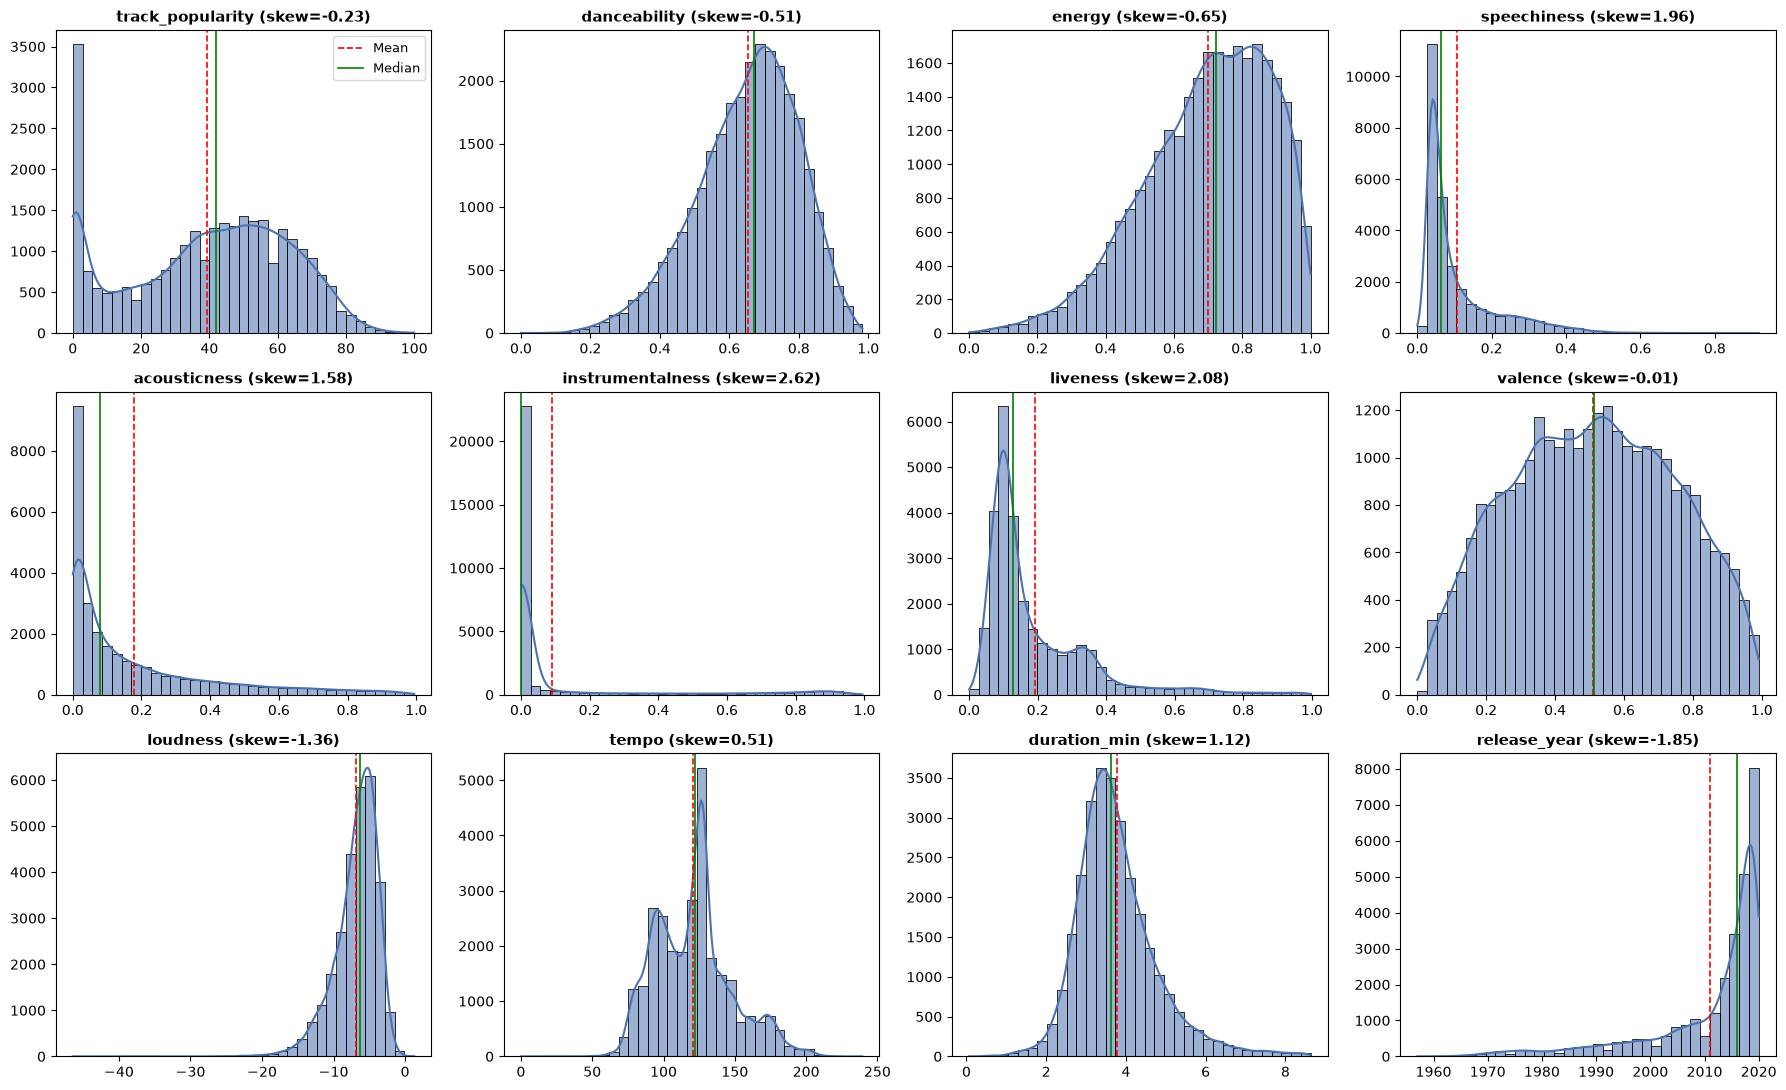

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    ax = axes[idx]
    data = tracks[col].dropna()

    sns.histplot(data, bins=35, kde=True, ax=ax, color='#4C72B0', alpha=0.55)
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.2, label='Mean')
    ax.axvline(data.median(), color='green', linestyle='-', linewidth=1.2, label='Median')

    ax.set_title(f"{col} (skew={data.skew():.2f})", fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    if idx == 0:
        ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### Đọc chỉ số theo định nghĩa của Spotify Web API
Nguồn định nghĩa: [Data dictionary, TidyTuesday 2020-01-21](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-01-21) (chép lại mô tả audio features của Spotify Web API).

Các cột âm thanh là điểm do mô hình nội bộ của Spotify chấm nên cần được xem xét kỹ khi quan sát:
1. Nhóm độ tin cậy :`acousticness`, `instrumentalness`, `liveness`
   - Nằm trong khoảng `[0, 1]` biểu thị confidence score.
   - Vì phân phối dồn sát về `0` (`instrumentalness` có `skew = 2.62`, `liveness` `2.08`, `acousticness` `1.58`), `median` và `IQR` ít mang ý nghĩa định lượng; tỉ lệ bài vượt ngưỡng mới là thông tin đáng nói.
2. Nhóm có ngưỡng tài liệu: `speechiness`, `instrumentalness`, `liveness`, `loudness`
   - `speechiness` (`skew = 1.96`): Spotify chia làm 3 vùng `< 0.33` (nhạc), `0.33–0.66` (nhạc lẫn lời nói, thường gặp ở rap), `> 0.66` (gần như toàn lời nói).
   - `instrumentalness`: `> 0.5` được coi là nhạc không lời.
   - `liveness`: `> 0.8` nhiều khả năng là bản thu trực tiếp (live).
   - `loudness` (`skew = -1.36`): dB trung bình cả bài, thường nằm trong `[-60, 0]`; xuất hiện một số giá trị `> 0 dB` (`max = 1.27`).
   - (`key` không có giá trị `-1` và `mode` gồm `1 = trưởng`, `0 = thứ` đã kiểm tra ở mục 2.1.)
3. Nhóm không có ngưỡng tài liệu: `danceability`, `energy`, `valence`, `tempo`
   - Có phân phối cân đối hơn (`|skew| ≤ 0.65`), nhưng Spotify không đặt ngưỡng cố định. Các giá trị như trung vị `danceability = 0.67` hay `valence = 0.51` chỉ dùng để mô tả mặt bằng chung và chỉ nên so sánh tương đối (ví dụ giữa các `genre` hoặc các năm ở phần sau), không thể diễn giải kiểu *"0.65 là nhảy nhiều"*.
4. `track_popularity` và `release_year`:
   - `release_year` lệch trái sâu (`skew = -1.85`, trung vị `2016`), phản ánh thiên lệch ưu tiên nhạc mới của các playlist (Sampling Bias nhắc ở mục 1).
   - `track_popularity` (0–100) được Spotify tính từ lượt nghe và nghiêng về lượt nghe gần đây (tại thời điểm 01/2020) (có thể là lý do vì sao nhiều bài có `track_popularity` gần hoặc bằng 0)
5. Điểm bất thường : Toàn bộ biến miền `[0, 1]` đều nằm đúng biên, nhưng có các trường hợp `tempo = 0.00`, `duration_min = 0.07` và `loudness > 0`.

### Kiểm tra tỉ lệ theo ngưỡng Spotify & các điểm bất thường

In [20]:
total = len(tracks)
threshold_rows = [
    ("speechiness < 0.33 (nhạc)", (tracks['speechiness'] < 0.33).sum()),
    ("speechiness 0.33–0.66 (nhạc lẫn lời nói / rap)", ((tracks['speechiness'] >= 0.33) & (tracks['speechiness'] <= 0.66)).sum()),
    ("speechiness > 0.66 (gần như toàn lời nói)", (tracks['speechiness'] > 0.66).sum()),
    ("instrumentalness > 0.5 (coi là nhạc không lời)", (tracks['instrumentalness'] > 0.5).sum()),
    ("instrumentalness == 0 (bằng 0 tuyệt đối)", (tracks['instrumentalness'] == 0).sum()),
    ("liveness > 0.8 (nhiều khả năng bản thu live)", (tracks['liveness'] > 0.8).sum()),
    ("acousticness > 0.5 (nghiêng về acoustic)", (tracks['acousticness'] > 0.5).sum()),
    ("loudness > 0 dB (vượt ngưỡng 0 dB)", (tracks['loudness'] > 0).sum()),
    ("tempo == 0 (không bắt được nhịp BPM)", (tracks['tempo'] == 0).sum()),
    ("duration_min < 0.5 (dưới 30 giây)", (tracks['duration_min'] < 0.5).sum()),
    ("duration_min > 8.0 (trên 8 phút)", (tracks['duration_min'] > 8.0).sum()),
    ("track_popularity == 0 (điểm phổ biến bằng 0)", (tracks['track_popularity'] == 0).sum()),
]

threshold_df = pd.DataFrame([
    {"Nhóm / Ngưỡng kiểm tra": desc, "Số bài": cnt, "Tỷ lệ (%)": round(cnt / total * 100, 2)}
    for desc, cnt in threshold_rows
])
display(threshold_df)

,Nhóm / Ngưỡng kiểm tra,Số bài,Tỷ lệ (%)
0,speechiness < 0.33 (nhạc),26852,94.70
1,speechiness 0.33–0.66 (nhạc lẫn lời nói / rap),1479,5.22
2,speechiness > 0.66 (gần như toàn lời nói),25,0.09
3,instrumentalness > 0.5 (coi là nhạc không lời),2569,9.06
4,instrumentalness == 0 (bằng 0 tuyệt đối),10175,35.88
5,liveness > 0.8 (nhiều khả năng bản thu live),298,1.05
6,acousticness > 0.5 (nghiêng về acoustic),3079,10.86
7,loudness > 0 dB (vượt ngưỡng 0 dB),6,0.02
8,tempo == 0 (không bắt được nhịp BPM),1,0.00
9,duration_min < 0.5 (dưới 30 giây),2,0.01


In [21]:
# Kiểm tra phân bố track_popularity == 0 theo thập kỷ phát hành
decade = (tracks['release_year'] // 10) * 10
pop_by_decade = tracks.groupby(decade)['track_popularity'].agg(
    so_bai='size',
    ty_le_bang_0_pct=lambda s: round((s == 0).mean() * 100, 2),
    median_popularity='median'
)
pop_by_decade.index.name = 'decade'
print("\nPhân bố track_popularity == 0 theo thập kỷ phát hành:")
display(pop_by_decade)


Phân bố track_popularity == 0 theo thập kỷ phát hành:


,so_bai,ty_le_bang_0_pct,median_popularity
decade,,,
1950,3,0.00,59.00
1960,132,4.55,56.50
1970,783,5.75,50.00
1980,1090,4.77,47.00
1990,2081,9.37,42.00
2000,3807,19.60,34.00
2010,19834,7.94,43.00
2020,626,0.16,43.00


In [22]:
# Quan sát bài bất thường về tempo == 0, duration_min < 0.5 hoặc loudness > 0
print("--- Các bài bất thường về tempo / loudness / duration ngắn ---")
weird_cond = (tracks['tempo'] == 0) | (tracks['loudness'] > 0) | (tracks['duration_min'] < 0.5)
display(
    tracks[weird_cond][
        ['track_name', 'track_artist', 'playlist_genre', 'tempo', 'loudness', 'duration_min']
    ]
)

--- Các bài bất thường về tempo / loudness / duration ngắn ---


,track_name,track_artist,playlist_genre,tempo,loudness,duration_min
8339,The Screwed Up Click,DJ Screw & The Screwed Up Click,rap,85.81,-8.51,0.49
9883,Nails,Ghostemane,rap,118.03,0.55,2.24
10438,Crema,Owin,rap,135.95,0.33,3.75
10458,Rockstar,Duki,rap,123.99,0.64,1.87
11363,"Hi, How're You Doin'?",DREAMS COME TRUE,rock,0.00,-26.09,0.07
12197,Raw Power - Iggy Pop Mix,The Stooges,rock,154.85,1.27,4.27
27716,Escape From Love - Curbi Remix,Eva Simons,edm,125.05,1.14,3.58
30339,Vidrado Em Você,Dj Guuga,edm,159.93,0.30,2.25


Ta quan sát được:
  - `speechiness`: **94,70%** (`26.852` bài) nằm dưới `0.33` (nhạc); **5,22%** (`1.479` bài) nằm trong `0.33–0.66` (nhạc lẫn lời nói/rap); chỉ **0,09%** (`25` bài) vượt `0.66` (gần như toàn lời nói).
  - `instrumentalness`: **9,06%** (`2.569` bài) vượt `0.5` được xem là nhạc không lời (trong khi `35,88%` bằng `0` tuyệt đối).
  - `liveness`: Chỉ **1,05%** (`298` bài) vượt `0.8`, chứng tỏ bản thu trực tiếp chiếm tỉ lệ rất nhỏ.
  - `acousticness`: **10,86%** (`3.079` bài) có độ tin cậy `> 0.5`.
- **`track_popularity == 0` (`9,24%`, `2.620` bài):** Tỉ lệ bằng `0` đạt đỉnh ở thập kỷ 2000s (`19,60%`, median = 34). Trong khi đó, các bài thập niên 1960–1980 có mặt trong tập dữ liệu lại giữ median popularity khá cao (`47–56,5`) do *thiên lệch sống sót* (chỉ các bản kinh điển còn được nghe mới xuất hiện trong playlist).
- Điểm bất thường kỹ thuật (`8` bài):
  - `tempo == 0.00` chỉ có **1 bài** (*Hi, How're You Doin'?*) dài `0,07` phút (~4 giây) — quá ngắn để ước lượng nhịp BPM.
  - `duration_min < 0.5` có **2 bài** (thêm *The Screwed Up Click* dài `0,49` phút).
  - `loudness > 0 dB` có **6 bài** (`0,02%`, tối đa `+1,27 dB`) ở các bản rock/rap/EDM master âm lượng rất cao.

### Kiểm tra ngoại lai (Outliers) theo quy tắc 1.5 × IQR

In [23]:
# 1. Bảng tổng hợp outlier theo quy tắc 1.5 * IQR cho toàn bộ 12 cột
outlier_rows = []
for col in num_cols:
    q1 = tracks[col].quantile(0.25)
    q3 = tracks[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((tracks[col] < lower) | (tracks[col] > upper)).sum()
    outlier_rows.append({
        'Cột': col,
        'Ngưỡng dưới': round(lower, 3),
        'Ngưỡng trên': round(upper, 3),
        'Số outlier': n_out,
        'Tỷ lệ (%)': round(n_out / len(tracks) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_rows).sort_values(by='Số outlier', ascending=False)
display(outlier_df)

,Cột,Ngưỡng dưới,Ngưỡng trên,Số outlier,Tỷ lệ (%)
5,instrumentalness,-0.01,0.02,6085,21.46
3,speechiness,-0.10,0.27,2725,9.61
11,release_year,1991.50,2035.50,2354,8.30
4,acousticness,-0.35,0.63,1911,6.74
6,liveness,-0.14,0.48,1623,5.72
10,duration_min,1.45,5.93,1197,4.22
8,loudness,-13.71,0.69,837,2.95
9,tempo,48.93,185.04,494,1.74
1,danceability,0.26,1.06,257,0.91
2,energy,0.18,1.24,222,0.78


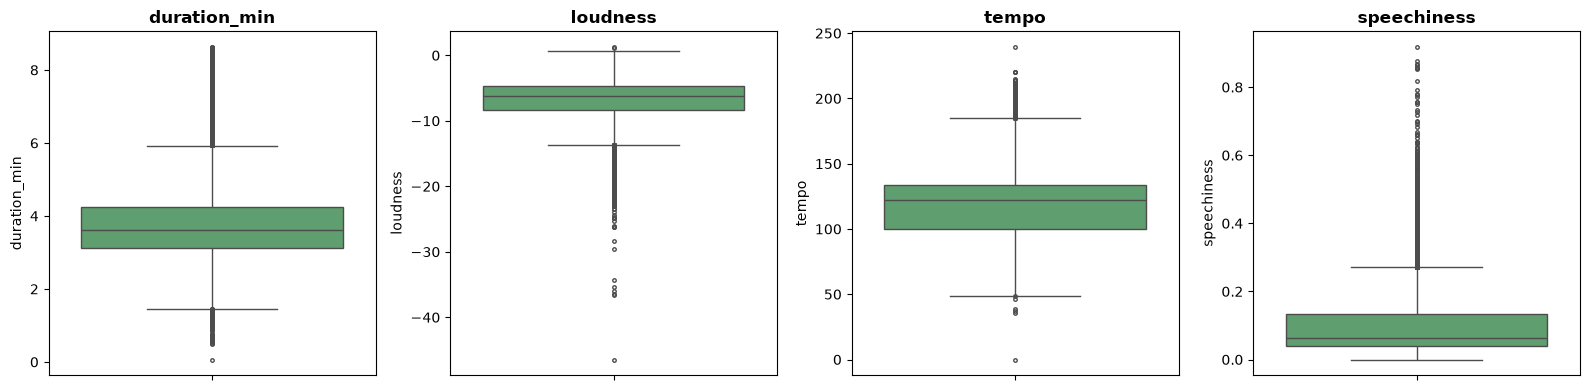

In [24]:
# 2. Vẽ Boxplot cho 4 cột tiêu biểu có cấu trúc outlier đáng chú ý
focus_cols = ['duration_min', 'loudness', 'tempo', 'speechiness']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, focus_cols):
    sns.boxplot(y=tracks[col], ax=ax, color='#55A868', fliersize=2.5)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [25]:
# 3. Mở xem tên bài hát ở nhóm cực trị để phân định Outlier thật vs Lỗi
print("--- Top 5 bài dài nhất (duration_min) ---")
display(tracks.nlargest(5, 'duration_min')[['track_name', 'track_artist', 'playlist_genre', 'duration_min']])

print("--- Top 5 bài có speechiness cao nhất ---")
display(tracks.nlargest(5, 'speechiness')[['track_name', 'track_artist', 'playlist_genre', 'speechiness']])

--- Top 5 bài dài nhất (duration_min) ---


,track_name,track_artist,playlist_genre,duration_min
21327,47 - Remix,Anuel AA,latin,8.63
11770,Kashmir - 2012 Remaster,Led Zeppelin,rock,8.62
12379,American Pie,Don McLean,rock,8.61
20643,Jam On It (Re-Recorded Version),Newcleus,latin,8.61
11919,Roundabout - 2008 Remaster,Yes,rock,8.60


--- Top 5 bài có speechiness cao nhất ---


,track_name,track_artist,playlist_genre,speechiness
25705,I'M DEAD,Duckwrth,r&b,0.92
8575,Keep It on Me,Dewey da Don,rap,0.88
4990,Warm Water - Snakehips Remix,BANKS,pop,0.87
5907,al pasito/timeless,n o r m a l,rap,0.86
7087,Intoxicated,Hitman Sammy Sam,rap,0.86


### Kết luận
- Không loại bỏ outlier bằng quy tắc `1.5 × IQR` dựa vào dữ liệu:
  - Tỉ lệ bị gắn cờ IQR cao ở `instrumentalness` (`21,46%`), `speechiness` (`9,61%`), `acousticness` (`6,74%`), `liveness` (`5,72%`) xuất phát từ phân phối lệch mạnh về `0` trên các **điểm tin cậy** — các giá trị cao chính là nhạc không lời, rap/lời nói, acoustic hoặc bản thu live có thật
  - Các bài có thời lượng dài (`duration_min > 5,93`, tối đa `8,63` phút như *Kashmir*, *American Pie*, *Roundabout*, *47 - Remix*) hay các bài phát hành trước `1991,5` (`8,30%`) đều là dữ liệu âm nhạc hợp lệ.
- Hướng xử lý ngoại lai ở bước tiền xử lý (tùy câu hỏi):
  - `tempo == 0` (1 bài dài 4 giây) và `duration_min < 0.5` (2 bài): cân nhắc lọc bỏ khi phân tích nhịp độ hoặc cấu trúc bài hát hoàn chỉnh.
  - `loudness > 0 dB` (6 bài, tối đa `1,27 dB`): giữ nguyên hoặc gắn cờ tùy bài toán.
  - `track_popularity == 0` (`9,24%`): không phải giá trị khuyết, nhưng chịu tác động của cơ chế ưu tiên lượt nghe gần đây của Spotify; cần lưu ý khi mô hình hóa hoặc so sánh giữa các thời kỳ.